# Original group notebook (archived as-is). Data paths point to the team's private Google Drive; see the repository README to run the refactored code.

# We have a README file to explain all our main files.

# Project Overview: Pipeline Recommendation System

This project implements a multi-stage recommendation pipeline that progressively narrows down the candidate set through filtering and re-ranking, aiming to improve both accuracy and diversity.

## Pipeline Steps

### 1. **TF-IDF Initial Filtering (500 items)**
- **Method**: Compute TF-IDF vectors from game text data (descriptions, tags, genres, etc.).
- **Process**: Calculate cosine similarity between each game's vector and the user's profile.
- **Output**: Select the top **500 candidate games** for each user.

### 2. **BERT Re-ranking (300 items)**
- **Method**: Use pre-trained Sentence-BERT to encode game text into semantic embeddings.
- **Process**: Re-rank the 500 candidates based on semantic similarity to the user profile.
- **Output**: Keep the top **300 candidates**.

### 3. **KNN Filtering (100 items)**
- **Method**: K-nearest neighbors based on user behavioral vectors (collaborative filtering).
- **Process**: From the 300 candidates, select the **100 most similar games** to the user.
- **Output**: Reduced candidate set to 100.

### 4. **SVD Final Ranking (10 items)**
- **Method**: Collaborative filtering via Singular Value Decomposition (SVD).
- **Process**: Predict ratings for the 100 candidates and sort them.
- **Output**: Recommend the **Top 10 games** to the user.



### Step 1: Load necessary libraries

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

!pip install scikit-surprise
!pip install seaborn
!pip install "numpy<2"

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.4/154.4 kB 12.2 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for scikit-surprise: filename=scikit_surprise-1.1.4-cp311-cp311-linux_x86_64.whl size=2469544 sha256=dbea0f3d733e22ae040cfcf334ac2be6e9177c6c630af517c8bf90de40cc64d1
  Stored in directory: /root/.cache/pip/wheels/2a/8f/6e/7e2899163e2d85d8266daab4aa1cdabec7a6c56f83c015b5af
Successfully built scikit-surprise
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.0/61.0 kB 4.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.3/18.3 MB 89.8 MB/s eta 0:00:00
  Attempting uninstall: numpy
    Found existing installation: numpy 2.0.2
    Uninstalling numpy-2.0.2:
      Successfully uninstalled numpy-2.0.2
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following 

### Step 2: Load the dataset

In [ ]:
import pandas as pd
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sentence_transformers import SentenceTransformer
from sklearn.preprocessing import MultiLabelBinarizer, MinMaxScaler
import pandas as pd
df = pd.read_csv('/content/drive/My Drive/9727-group/merged_filtered_games.csv')
game_df = df.drop_duplicates(subset='app_id').reset_index(drop=True)

### Step 3: Concatenate features for BERT embedding

In [ ]:
def concat_features(row):
    return ' '.join([
        str(row.get('About the game', '')),
        str(row.get('Tags', '')),
        str(row.get('genre', '')),
        str(row.get('Categories', '')),
        str(row.get('Developers', '')),
        str(row.get('Publishers', ''))
    ])

game_df['combined_features'] = game_df.apply(concat_features, axis=1)

### Step 4:  TF-IDF features from text

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
# TF-IDF vector
vectorizer = TfidfVectorizer(stop_words='english', max_features=5000)
tfidf_matrix = vectorizer.fit_transform(game_df['About the game'].fillna(''))
app_id_to_index = {aid: i for i, aid in enumerate(game_df['app_id'])}

### Step 5: BERT embedding

In [ ]:
model = SentenceTransformer('all-MiniLM-L6-v2')
bert_embeddings = model.encode(game_df['combined_features'].tolist(), show_progress_bar=True)

/usr/local/lib/python3.11/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

...

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/115 [00:00<?, ?it/s]

### Step 6: genre one-hot

In [ ]:
# genre one-hot
def split_and_strip(s):
    if pd.isna(s): return []
    return [x.strip() for x in str(s).replace(';', ',').split(',') if x.strip()]

game_df['genres_list'] = game_df['genre'].apply(split_and_strip)
mlb = MultiLabelBinarizer()
genre_matrix = mlb.fit_transform(game_df['genres_list'])

### Step 7: price normalize

In [ ]:
game_df['Price'] = pd.to_numeric(game_df['Price'], errors='coerce').fillna(0)
scaler = MinMaxScaler()
game_df['Price_norm'] = scaler.fit_transform(game_df[['Price']])

### Step 8: Define a function to get user profile based on played games

In [ ]:
def get_user_profile(user_id):
    played = df[(df['user_id'] == user_id)]
    if played.empty:
        return None

    valid_indices, weights = [], []
    for _, row in played.iterrows():
        app_id = row['app_id']
        if app_id in app_id_to_index:
            valid_indices.append(app_id_to_index[app_id])
            weights.append(row['hours'])

    if not valid_indices:
        return None

    weights = np.array(weights)
    tfidf_vector = np.asarray(tfidf_matrix[valid_indices].mean(axis=0)).flatten()
    content_vec = np.average(bert_embeddings[valid_indices], axis=0, weights=weights)
    genre_vec = np.average(genre_matrix[valid_indices], axis=0, weights=weights)
    price_pref = game_df.iloc[valid_indices]['Price_norm'].mean()

    return tfidf_vector, content_vec, genre_vec, price_pref

### Step 9: tf-idf

In [ ]:
def tfidf_recall(user_id, top_n=500):
    profile = get_user_profile(user_id)
    if profile is None:
        print(f"[TF-IDF] User {user_id} has no positive history.")
        return pd.DataFrame()

    tfidf_vector, _, _, _ = profile
    tfidf_vector_dense = np.asarray(tfidf_vector).reshape(1, -1)
    tfidf_scores = cosine_similarity(tfidf_vector_dense, tfidf_matrix).flatten()

    played_ids = set(df[df['user_id'] == user_id]['app_id'])
    sorted_indices = tfidf_scores.argsort()[::-1]

    filtered_indices = [i for i in sorted_indices if game_df.iloc[i]['app_id'] not in played_ids][:top_n]

    result = game_df.iloc[filtered_indices][['app_id', 'genre']].copy()
    result['tfidf_score'] = tfidf_scores[filtered_indices]
    result['user_id'] = user_id
    return result.reset_index(drop=True)

# BERT rerank
def rerank_with_bert(tfidf_candidates, user_id, top_n=300, alpha=0.7, beta=0.2, gamma=0.1):
    profile = get_user_profile(user_id)
    if profile is None:
        print(f"[BERT] User {user_id} has no positive history.")
        return pd.DataFrame()

    _, user_content, user_genre, user_price = profile

    # Ensure candidates are valid
    candidate_indices = [app_id_to_index[app] for app in tfidf_candidates['app_id'] if app in app_id_to_index]

    content_scores = np.dot(bert_embeddings[candidate_indices], user_content)
    genre_scores = genre_matrix[candidate_indices] @ user_genre
    price_scores = 1 - np.abs(game_df.iloc[candidate_indices]['Price_norm'].values - user_price)

    final_scores = alpha * content_scores + beta * genre_scores + gamma * price_scores
    top_k_idx = np.argsort(final_scores)[::-1][:top_n]
    final_indices = [candidate_indices[i] for i in top_k_idx]

    result = game_df.iloc[final_indices][['app_id', 'genre', 'Price']].copy()
    result['final_score'] = final_scores[top_k_idx]
    result['user_id'] = user_id
    return result.reset_index(drop=True)

### Step 9: show data

In [ ]:
user_id = 11553593

# tf -idf 500 games
tfidf_candidates = tfidf_recall(user_id, top_n=500)
print("\nTF-IDF Top 500:")
print(tfidf_candidates[['app_id', 'tfidf_score']])

# BERT 300 games
final_recommendations = rerank_with_bert(tfidf_candidates, user_id, top_n=300)
print("\nBERT Top 300:")
print(final_recommendations[['app_id', 'final_score']])


TF-IDF Top 500:
     app_id  tfidf_score
0    555570     0.362573
1    373420     0.353347
2    394690     0.351837
3    356650     0.346943
4    337320     0.343970
..      ...          ...
495   40100     0.231491
496  629910     0.231077
497   48700     0.230956
498  232890     0.230942
499  577940     0.230897

[500 rows x 2 columns]

BERT Top 300:
      app_id  final_score
0     204360     0.757835
1     994220     0.752393
2     629910     0.749044
3     538100     0.746637
4     378370     0.744346
..       ...          ...
295   359840     0.508328
296  1509960     0.508061
297   396900     0.507422
298   546050     0.506418
299    17330     0.505811

[300 rows x 2 columns]


### Step 10： Construct the final DataFrame

In [ ]:
def build_content_based_df_for_all_users(tfidf_top_n=500, final_top_n=300):
    unique_users = df['user_id'].unique()
    result_rows = []

    for uid in unique_users:
        tfidf_candidates = tfidf_recall(uid, top_n=tfidf_top_n)
        if tfidf_candidates.empty:
            continue

        final_recs = rerank_with_bert(tfidf_candidates, uid, top_n=final_top_n)
        if final_recs.empty:
            continue

        app_ids = final_recs['app_id'].tolist()

        # Ensure each user-app pair is unique
        for app_id in app_ids:
            result_rows.append({
                'user_id': uid,
                'app_id': app_id
            })

    return pd.DataFrame(result_rows)


content_based_df = build_content_based_df_for_all_users()
content_based_df.to_csv('/content/drive/My Drive/9727-group/content_base_result.csv', index=False)
print("Saved to content_base_result.csv")

Saved to content_base_result.csv


In [ ]:
import pandas as pd

# Load new users' history data
user_sport = pd.read_csv('/content/drive/My Drive/9727-group/user_sport.csv', encoding='gbk')
user_cod = pd.read_csv('/content/drive/My Drive/9727-group/user_call_of_duty.csv', encoding='gbk')
new_user_history = pd.concat([user_sport, user_cod], ignore_index=True)
df = pd.concat([df, new_user_history], ignore_index=True)
new_user_ids = new_user_history['user_id'].unique()

def recommend_for_multiple_users(user_ids, tfidf_top_n=500, final_top_n=300):
    result_rows = []

    for uid in user_ids:
        tfidf_candidates = tfidf_recall(uid, top_n=tfidf_top_n)
        if tfidf_candidates.empty:
            print(f"[TF-IDF] User {uid} has no positive history.")
            continue

        final_recs = rerank_with_bert(tfidf_candidates, uid, top_n=final_top_n)
        if final_recs.empty:
            continue

        for app_id in final_recs['app_id'].tolist():
            result_rows.append({
                'user_id': uid,
                'app_id': app_id
            })

    return pd.DataFrame(result_rows)

new_user_recs = recommend_for_multiple_users(new_user_ids)


new_user_recs.to_csv('/content/drive/My Drive/9727-group/new_user_recommendations.csv', index=False)
print("New user recommendations saved to new_user_recommendations.csv")

New user recommendations saved to new_user_recommendations.csv


In [ ]:
display(new_user_recs)

,user_id,app_id
0,22222222,703860
1,22222222,1531720
2,22222222,228380
3,22222222,670290
4,22222222,1292630
...,...,...
595,11111111,9200
596,11111111,235210
597,11111111,1167450
598,11111111,380840


#Then is CF-KNN Method.
# KNN Filtering (100 items)
**Method: K-nearest neighbors based on user behavioral vectors (collaborative filtering).
Process: From the 300 candidates, select the 100 most similar games to the user.
Output: Reduced candidate set to 100.**

In [ ]:
# import pandas as pd
# import matplotlib.pyplot as plt

# # Careful: It might be better to install these outside Jupyter
# !pip install scikit-surprise
# !pip install seaborn
# !pip install "numpy<2"

In [ ]:
# filtered_games.csv is used for training.
import pandas as pd
user_dataset = pd.read_csv("/content/drive/My Drive/9727-group/filtered_games.csv")
display(user_dataset)
user_dataset['user_id'] = user_dataset['user_id'].astype(str).str.strip()
user_dataset['app_id'] = user_dataset['app_id'].astype(str).str.strip()

unique_game_count = user_dataset['app_id'].nunique()
print("unique games count:", unique_game_count)
unique_user_count = user_dataset['user_id'].nunique()
print("unique users count:", unique_user_count)

,app_id,is_recommended,hours,user_id,genre
0,1196590,1.0,19.0,5935019,Action
1,435150,1.0,199.9,6334645,"Adventure,RPG,Strategy"
2,275850,1.0,13.6,6484333,"Action,Adventure"
3,105600,1.0,911.8,10383001,"Action,Adventure,Indie,RPG"
4,1794680,1.0,77.3,11659871,"Action,Casual,Indie,RPG,Early Access"
...,...,...,...,...,...
950350,253430,0.0,1.0,2444255,"Violent,Action,Adventure,Indie"
950351,897450,1.0,6.0,8857084,"Action,Adventure,Casual,Indie"
950352,1818450,1.0,1.0,13261742,"Action,Adventure,Massively Multiplayer,RPG"
950353,362960,1.0,35.0,7858713,"Adventure,RPG"


unique games count: 3654
unique users count: 8225


In [ ]:
# Then add two real users into filtered_games.csv dataset.

import pandas as pd
# Add two real users to the original dataset.
# Load the user_sport_csv
sport_csv_path = "/content/drive/My Drive/9727-group/user_sport.csv"
sport_dataset = pd.read_csv(sport_csv_path, encoding='ISO-8859-1')

fps_csv_path = "/content/drive/My Drive/9727-group/user_call_of_duty.csv"
fps_dataset = pd.read_csv(fps_csv_path, encoding='ISO-8859-1')

# changae and equal the datatype
sport_dataset['user_id'] = sport_dataset['user_id'].astype(str)
sport_dataset['app_id'] = sport_dataset['app_id'].astype(str)
fps_dataset['user_id'] = fps_dataset['user_id'].astype(str)
fps_dataset['app_id'] = fps_dataset['app_id'].astype(str)
user_dataset['user_id'] = user_dataset['user_id'].astype(str)
user_dataset['app_id'] = user_dataset['app_id'].astype(str)

# Keep the needed.
sport_data_filtered = sport_dataset[['user_id', 'app_id', 'is_recommended']].copy()
fps_data_filtered = fps_dataset[['user_id', 'app_id', 'is_recommended']].copy()
user_data_filtered = user_dataset[['user_id', 'app_id', 'is_recommended']].copy()

# form the training set.
train_df = pd.concat([user_data_filtered, sport_data_filtered, fps_data_filtered], ignore_index=True)
display(train_df)

,user_id,app_id,is_recommended
0,5935019,1196590,1.0
1,6334645,435150,1.0
2,6484333,275850,1.0
3,10383001,105600,1.0
4,11659871,1794680,1.0
...,...,...,...
950392,11111111,284160,1.0
950393,11111111,609490,1.0
950394,11111111,253430,1.0
950395,11111111,793350,1.0


In [ ]:
# achieved the final training set.
from surprise import KNNBasic
from surprise import Dataset, Reader
from surprise import SVD
from surprise import Dataset, Reader
from sklearn.model_selection import train_test_split
import random
import pandas as pd
from surprise.model_selection import train_test_split
reader = Reader(rating_scale=(0, 1))
data = Dataset.load_from_df(train_df[['user_id', 'app_id', 'is_recommended']], reader)
# trainset, testset = train_test_split(data, test_size=0.2, random_state=42)
trainset = data.build_full_trainset()

In [ ]:
# method 1: KNN.
from surprise import KNNBasic
# item-based CF
sim_options = {
    'name': 'cosine',
    'user_based': False     # Item-based
}
algo = KNNBasic()
algo.fit(trainset)

Computing the msd similarity matrix...
Done computing similarity matrix.


In [ ]:
# Read the top300 recommanded games for each user.
import pandas as pd
# Read from csv file.
cb_df = pd.read_csv("/content/drive/My Drive/9727-group/new_user_recommendations.csv")
cb_df['user_id'] = cb_df['user_id'].astype(str).str.strip()
cb_df['app_id'] = cb_df['app_id'].astype(str).str.strip()
display(cb_df)
unique_user_count = cb_df['user_id'].nunique()
print("Unique user in cb_df:", unique_user_count)
unique_game_count = cb_df['app_id'].nunique()
print("Unique game in cb_df:", unique_game_count)

,user_id,app_id
0,22222222,703860
1,22222222,1531720
2,22222222,228380
3,22222222,670290
4,22222222,1292630
...,...,...
595,11111111,9200
596,11111111,235210
597,11111111,1167450
598,11111111,380840


Unique user in cb_df: 2
Unique game in cb_df: 484


In [ ]:
# Create the anti_testset in Surprise style.
cb_testset = [(str(row.user_id), str(row.app_id), 0) for _, row in cb_df.iterrows()]
predictions = algo.test(cb_testset)

In [ ]:
# Top-100 outcomes for each user.
def get_top_n_recommendations(predictions, n=100):
    top_n = {}
    for uid, iid, true_r, est, _ in predictions:
        top_n.setdefault(uid, []).append((iid, est))
    for uid, user_ratings in top_n.items():
        user_ratings.sort(key=lambda x: x[1], reverse=True)
        top_n[uid] = user_ratings[:n]
    return top_n

top_n = get_top_n_recommendations(predictions, n=100)

# recommend 100/500 after cf-knn method
for uid, user_ratings in list(top_n.items())[:3]:
    print(f"Top 10 recommendations for user {uid}: {', '.join([str(iid) for iid, _ in user_ratings])}")

Top 10 recommendations for user 22222222: 238460, 1369670, 304930, 107100, 848480, 200710, 386940, 345180, 1217060, 1509960, 326460, 531510, 1426210, 1290000, 785790, 610180, 759740, 415200, 201790, 880940, 312530, 322330, 222880, 41070, 220240, 469820, 500260, 941460, 1408230, 269770, 1211020, 243800, 553310, 269670, 219990, 632360, 373420, 251470, 577940, 286160, 1079800, 747200, 673750, 1929870, 1477590, 1288320, 228380, 843380, 686200, 1048540, 399820, 220820, 368340, 416600, 448510, 1016920, 322110, 322500, 546050, 728880, 337320, 509980, 94200, 666140, 495420, 1066890, 851800, 585710, 1227650, 1161490, 1718570, 846470, 1273710, 855860, 891040, 1163130, 394690, 204360, 261180, 356650, 34270, 895870, 1097840, 617830, 418530, 360940, 262830, 206500, 677620, 261550, 1238820, 555880, 1904540, 477770, 1243830, 410340, 362490, 473770, 1664220, 1328660
Top 10 recommendations for user 11111111: 222880, 1358710, 1922560, 9010, 1718570, 688470, 6060, 620, 337320, 550, 525510, 563560, 142621

In [ ]:
def get_top_n_recommendations_with_scores(predictions, n=100):
    top_n = {}
    for uid, iid, true_r, est, _ in predictions:
        top_n.setdefault(uid, []).append((iid, est))

    for uid, user_ratings in top_n.items():
        user_ratings.sort(key=lambda x: x[1], reverse=True)
        top_n[uid] = user_ratings[:n]

    return top_n

top_n = get_top_n_recommendations_with_scores(predictions, n=100)

for uid, user_ratings in list(top_n.items())[:5]:
    print(f"Top 10 recommendations for user {uid}:")
    for iid, est in user_ratings:
        print(f"    Game ID: {iid} | Predicted Score: {est:.3f}")

Top 10 recommendations for user 22222222:
    Game ID: 238460 | Predicted Score: 1.000
    Game ID: 1369670 | Predicted Score: 1.000
    Game ID: 304930 | Predicted Score: 1.000
    Game ID: 107100 | Predicted Score: 1.000
    Game ID: 848480 | Predicted Score: 0.979
    Game ID: 200710 | Predicted Score: 0.975
    Game ID: 386940 | Predicted Score: 0.975
    Game ID: 345180 | Predicted Score: 0.975
    Game ID: 1217060 | Predicted Score: 0.975
    Game ID: 1509960 | Predicted Score: 0.975
    Game ID: 326460 | Predicted Score: 0.975
    Game ID: 531510 | Predicted Score: 0.975
    Game ID: 1426210 | Predicted Score: 0.975
    Game ID: 1290000 | Predicted Score: 0.975
    Game ID: 785790 | Predicted Score: 0.975
    Game ID: 610180 | Predicted Score: 0.975
    Game ID: 759740 | Predicted Score: 0.959
    Game ID: 415200 | Predicted Score: 0.950
    Game ID: 201790 | Predicted Score: 0.950
    Game ID: 880940 | Predicted Score: 0.950
    Game ID: 312530 | Predicted Score: 0.950
    Game

In [ ]:
recommendation_pairs = [
    (uid, iid) for uid, user_ratings in top_n.items() for (iid, _) in user_ratings
]

# Create the DataFrame.
recommendation_df = pd.DataFrame(recommendation_pairs, columns=['user_id', 'app_id'])

# Create the CSV.
recommendation_df.to_csv('/content/drive/My Drive/9727-group/real_user_cf_knn_top100.csv', index=False)

In [ ]:
# Check the results.
print(recommendation_df.head(10))
import pandas as pd

before_svd_df = pd.read_csv("/content/drive/My Drive/9727-group/real_user_cf_knn_top100.csv")
display(before_svd_df)

unique_user_count = before_svd_df['user_id'].nunique()
print("unique users count:", unique_user_count)

    user_id   app_id
0  22222222   238460
1  22222222  1369670
2  22222222   304930
3  22222222   107100
4  22222222   848480
5  22222222   200710
6  22222222   386940
7  22222222   345180
8  22222222  1217060
9  22222222  1509960


,user_id,app_id
0,22222222,238460
1,22222222,1369670
2,22222222,304930
3,22222222,107100
4,22222222,848480
...,...,...
195,11111111,312660
196,11111111,394510
197,11111111,300380
198,11111111,102840


unique users count: 2


#Then is CF-SVD Method.
# SVD Filtering, get the final 10 recommendations for test users
**Method: SVD based on user behavioral vectors (collaborative filtering).
Process: From the 100 candidates, select the final 10 most similar games to the user.
Output: 10 recommendations**

In [ ]:
# import pandas as pd
# import matplotlib.pyplot as plt

# !pip install scikit-surprise
# !pip install seaborn
# !pip install "numpy<2"

    app_id  is_recommended  hours   user_id  \
0  1196590             1.0   19.0   5935019   
1   435150             1.0  199.9   6334645   
2   275850             1.0   13.6   6484333   
3   105600             1.0  911.8  10383001   
4  1794680             1.0   77.3  11659871   

                                  genre  rating  
0                                Action       4  
1                Adventure,RPG,Strategy       5  
2                      Action,Adventure       3  
3            Action,Adventure,Indie,RPG       5  
4  Action,Casual,Indie,RPG,Early Access       5  
unique games count: 3654
unique user count: 8225


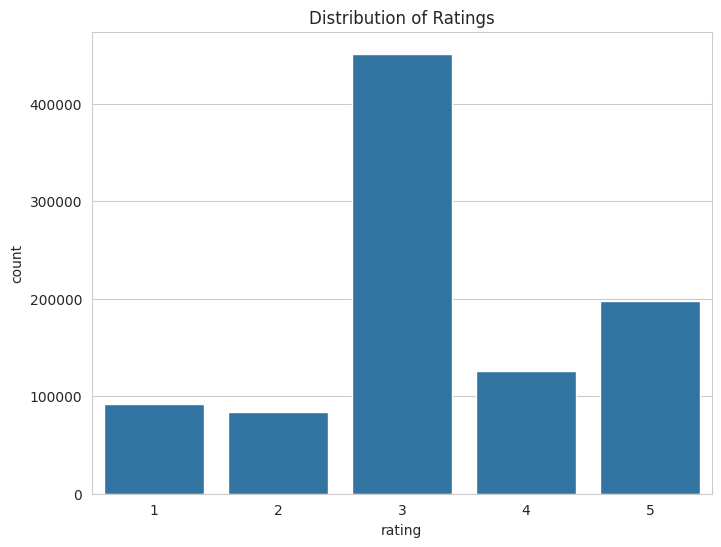

In [ ]:
from tqdm import tqdm
# tqdm.pandas()
# filtered_df['rating'] = filtered_df.progress_apply(assign_rating, axis=1)
# filtered_df.to_csv("/content/drive/My Drive/9727group/filtered_games_with_rating.csv", index=False)

csv_path = "/content/drive/My Drive/9727-group/filtered_games_with_rating.csv"
user_dataset = pd.read_csv(csv_path)
user_dataset['user_id'] = user_dataset['user_id'].astype(str).str.strip()
user_dataset['app_id'] = user_dataset['app_id'].astype(str).str.strip()
print(user_dataset.head())

unique_game_count = user_dataset['app_id'].nunique()
print("unique games count:", unique_game_count)
unique_user_count = user_dataset['user_id'].nunique()
print("unique user count:", unique_user_count)

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
plt.figure(figsize=(8,6))
sns.countplot(x='rating', data=user_dataset)
plt.title('Distribution of Ratings')
plt.show()

In [ ]:
from surprise import SVD
from surprise import Dataset, Reader
from sklearn.model_selection import train_test_split
import random
import pandas as pd
from tqdm import tqdm
tqdm.pandas()
RANDOM_STATE = 42
random.seed(RANDOM_STATE)

def assign_rating(row):
    if row['is_recommended'] and row['hours'] >= 25:
        return 5
    elif row['is_recommended'] and row['hours'] >= 10:
        return 4
    elif row['is_recommended']:
        return 3
    elif row['hours'] >= 5:
        return 2
    else:
        return 1

# sport_csv_path = "/content/drive/My Drive/9727group/user_sport.csv"
# sport_dataset = pd.read_csv(sport_csv_path)
# sport_dataset['rating'] = sport_dataset.progress_apply(assign_rating, axis=1)
sport_csv_path = "/content/drive/My Drive/9727-group/user_sport.csv"
sport_dataset = pd.read_csv(sport_csv_path, encoding='ISO-8859-1')
sport_dataset['rating'] = sport_dataset.progress_apply(assign_rating, axis=1)
print(sport_dataset.head())


fps_csv_path = "/content/drive/My Drive/9727-group/user_call_of_duty.csv"
fps_dataset = pd.read_csv(fps_csv_path,  encoding='ISO-8859-1')
fps_dataset['rating'] = fps_dataset.progress_apply(assign_rating, axis=1)
print(fps_dataset.head())


# unify the format
sport_dataset['user_id'] = sport_dataset['user_id'].astype(str)
sport_dataset['app_id'] = sport_dataset['app_id'].astype(str)
fps_dataset['user_id'] = fps_dataset['user_id'].astype(str)
fps_dataset['app_id'] = fps_dataset['app_id'].astype(str)
user_dataset['user_id'] = user_dataset['user_id'].astype(str)
user_dataset['app_id'] = user_dataset['app_id'].astype(str)

# get the real uers' data
sport_data_filtered = sport_dataset[['user_id', 'app_id', 'rating']].copy()
fps_data_filtered = fps_dataset[['user_id', 'app_id', 'rating']].copy()

print(sport_data_filtered.head())
print(fps_data_filtered.head())

train_rows = []
test_rows = []

for uid, group in user_dataset.groupby('user_id'):
      train_part, test_part = train_test_split(group, test_size=0.2, random_state=RANDOM_STATE)
      train_rows.append(train_part)
      test_rows.append(test_part)


pre_train_df = pd.concat(train_rows)
test_df = pd.concat(test_rows)

# merging real users' data with origin one
train_df = pd.concat([pre_train_df, sport_data_filtered, fps_data_filtered], ignore_index=True)


unique_test_games = test_df['app_id'].nunique()

reader = Reader(rating_scale=(1,5))
train_data = Dataset.load_from_df(train_df[['user_id', 'app_id', 'rating']], reader)
trainset = train_data.build_full_trainset()

testset = list(test_df[['user_id', 'app_id', 'rating']].itertuples(index=False, name=None))


from surprise import SVD
from surprise.model_selection import GridSearchCV
param_grid = {
    'n_factors': [100],
    'reg_all': [0.02]
}


gs = GridSearchCV(SVD, param_grid, measures=['rmse'], cv=3)
gs.fit(train_data)

#Get the optimal parameters
print("Best RMSE score attained: ", gs.best_score['rmse'])
print("Best parameters: ", gs.best_params['rmse'])

# training with the optimal parameters
best_algo = gs.best_estimator['rmse']
best_algo.fit(trainset)

predictions = best_algo.test(testset)

for pred in predictions[:5]:
    print(pred)

from surprise import accuracy

accuracy.rmse(predictions)


100%|██████████| 18/18 [00:00<00:00, 13215.03it/s]


    app_id  is_recommended       hours   user_id  \
0   960170               1  137.693657  22222222   
1   207140               1    9.420437  22222222   
2   681280               0   95.964967  22222222   
3  1506830               1  113.220339  22222222   
4   212480               1  139.873221  22222222   

                               genre  \
0               Action,Casual,Sports   
1  Action,Casual,Indie,Racing,Sports   
2               Action,Racing,Sports   
3                  Simulation,Sports   
4                      Racing,Sports   

                                      About the game  \
0  DJMAX RESPECT V delivers an unrivaled rhythm g...   
1  In a city filled with superheroes, getting to ...   
2  From the developers of Action Henk , Descender...   
3  Powered by Football?, EA SPORTS? FIFA 22 bring...   
4  Sonic and the All-Stars cast line up on the st...   

                                                Tags  \
0  Rhythm,Casual,Action,Music,Sports,Great Soundt... 

100%|██████████| 24/24 [00:00<00:00, 16752.09it/s]


    app_id  is_recommended      hours   user_id             genre  \
0   311210               1  48.511753  11111111  Action,Adventure   
1  1238880               1  79.786204  11111111            Action   
2  1938090               1  72.481927  11111111            Action   
3   202970               1   5.701436  11111111            Action   
4    42700               1  82.550724  11111111            Action   

                                      About the game  \
0  Call of Duty?: Black Ops III Zombies Chronicle...   
1  Strategy. Speed. Story. These are the core pil...   
2  Existing Modern Warfare? II Digital Standard E...   
3  Pushing the boundaries of what fans have come ...   
4  The biggest first-person action series of all ...   

                                                Tags  \
0  Multiplayer,FPS,Zombies,Shooter,Action,First-P...   
1  Action,Multiplayer,Singleplayer,Shooter,FPS,Wa...   
2  FPS,Action,Multiplayer,Shooter,Military,First-...   
3  Action,Multiplayer,FP

1.0047683074047193

In [ ]:
import pandas as pd
# cb_df = pd.read_csv("/content/drive/My Drive/9727group/cf_knn_top100.csv")
cb_df = pd.read_csv("/content/drive/My Drive/9727-group/real_user_cf_knn_top100.csv")

cb_df['user_id'] = cb_df['user_id'].astype(str).str.strip()
cb_df['app_id'] = cb_df['app_id'].astype(str).str.strip()


display(cb_df)

missing_users = set()
missing_items = set()
known_pairs = 0
total_pairs = 0

for _, row in cb_df.iterrows():
    uid = row.user_id
    iid = row.app_id
    total_pairs += 1

    user_known = True
    item_known = True

    try:
        trainset.to_inner_uid(uid)
    except ValueError:
        user_known = False
        missing_users.add(uid)

    try:
        trainset.to_inner_iid(iid)
    except ValueError:
        item_known = False
        missing_items.add(iid)

    if user_known and item_known:
        known_pairs += 1

print(f"Missing users: {len(missing_users)}")
print(f"Missing items: {len(missing_items)}")
print(f"{known_pairs}/{total_pairs} pairs are known to trainset.")

cb_testset = [(str(row.user_id), str(row.app_id), 0) for _, row in cb_df.iterrows()]
predictions = best_algo.test(cb_testset)

,user_id,app_id
0,22222222,238460
1,22222222,1369670
2,22222222,304930
3,22222222,107100
4,22222222,848480
...,...,...
195,11111111,312660
196,11111111,394510
197,11111111,300380
198,11111111,102840


Missing users: 0
Missing items: 0
200/200 pairs are known to trainset.


In [ ]:
# Top-N
def get_top_n_recommendations_with_scores(predictions, n=10):
    top_n = {}
    for uid, iid, true_r, est, _ in predictions:
        top_n.setdefault(uid, []).append((iid, est))

    for uid, user_ratings in top_n.items():
        user_ratings.sort(key=lambda x: x[1], reverse=True)
        top_n[uid] = user_ratings[:n]

    return top_n

top_n = get_top_n_recommendations_with_scores(predictions, n=10)

for uid, user_ratings in list(top_n.items())[:10]:
    print(f"Top 10 recommendations for user {uid}:")
    for iid, est in user_ratings:
        print(f"    Game ID: {iid} | Predicted Score: {est:.3f}")

Top 10 recommendations for user 22222222:
    Game ID: 200710 | Predicted Score: 4.967
    Game ID: 219990 | Predicted Score: 4.890
    Game ID: 1290000 | Predicted Score: 4.874
    Game ID: 1217060 | Predicted Score: 4.745
    Game ID: 373420 | Predicted Score: 4.685
    Game ID: 495420 | Predicted Score: 4.589
    Game ID: 394690 | Predicted Score: 4.584
    Game ID: 220240 | Predicted Score: 4.581
    Game ID: 415200 | Predicted Score: 4.562
    Game ID: 41070 | Predicted Score: 4.416
Top 10 recommendations for user 11111111:
    Game ID: 790820 | Predicted Score: 5.000
    Game ID: 550 | Predicted Score: 4.983
    Game ID: 239140 | Predicted Score: 4.877
    Game ID: 48700 | Predicted Score: 4.812
    Game ID: 367500 | Predicted Score: 4.798
    Game ID: 8980 | Predicted Score: 4.788
    Game ID: 220240 | Predicted Score: 4.756
    Game ID: 1217060 | Predicted Score: 4.728
    Game ID: 238010 | Predicted Score: 4.686
    Game ID: 1007040 | Predicted Score: 4.672


In [ ]:

top_n_rows = []
for uid, user_ratings in top_n.items():
    for iid, est in user_ratings:
        top_n_rows.append({
            "user_id": uid,
            "app_id": iid,
            "predicted_rating": round(est, 3)
        })


top_n_df = pd.DataFrame(top_n_rows)

top_n_df.to_csv('/content/drive/My Drive/9727-group/cf_svd_top10.csv', index=False)

print(top_n_df.head())

    user_id   app_id  predicted_rating
0  22222222   200710             4.967
1  22222222   219990             4.890
2  22222222  1290000             4.874
3  22222222  1217060             4.745
4  22222222   373420             4.685


In [ ]:
final_result_pipline = pd.read_csv("/content/drive/My Drive/9727-group/cf_svd_top10.csv")
display(final_result_pipline)

,user_id,app_id,predicted_rating
0,22222222,200710,4.967
1,22222222,219990,4.890
2,22222222,1290000,4.874
3,22222222,1217060,4.745
4,22222222,373420,4.685
5,22222222,495420,4.589
6,22222222,394690,4.584
7,22222222,220240,4.581
8,22222222,415200,4.562
9,22222222,41070,4.416
